## Sprint 3 findings

- **Warming trend:** yearly average temperature is rising about **0.64 °F per decade**, roughly **2.8 °F** from 1981 to 2025 (linear regression).
- **Warmest year:** 2012, which also beat the trend line by the most. **Coldest year:** 1996.
- **Hot days:** the usual 90 °F cutoff gives only 4 days in 45 years, because NASA POWER's ~50 km grid square smooths out city heat (top high in the data is 93.6 °F). So a hot day here means the hottest 5% of days: a high of **81 °F or more**.
- Hot days are rising about **+3 per decade**, from **12.3 a year (1981–1990)** to **24.1 a year (2016–2025)**, roughly double. The record was **2010 with 43**.
- **Caveat:** a straight line is a simple model. It shows the overall direction, but it shouldn't be stretched far into the future.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/nyc_daily_1981_2025.csv", index_col="date", parse_dates=True)

df["year"] = df.index.year
df["T2M_F"] = df["T2M"] * 9 / 5 + 32
df["T2M_MAX_F"] = df["T2M_MAX"] * 9 / 5 + 32

df.head()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,year,T2M_F,T2M_MAX_F
date,,,,,,,,
1981-01-01,-2.33,-1.28,-3.56,0.50,79.31,1981,27.806,29.696
1981-01-02,-1.12,1.64,-5.48,1.09,77.30,1981,29.984,34.952
1981-01-03,-4.38,-1.33,-6.69,0.93,84.84,1981,24.116,29.606
1981-01-04,-10.22,-6.10,-11.94,0.06,92.84,1981,13.604,21.020
1981-01-05,-6.06,-2.24,-9.18,0.02,87.55,1981,21.092,27.968


In [2]:
df.tail()

,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,year,T2M_F,T2M_MAX_F
date,,,,,,,,
2025-12-27,0.38,3.05,-2.31,1.96,92.07,2025,32.684,37.490
2025-12-28,0.09,4.94,-2.85,0.15,87.17,2025,32.162,40.892
2025-12-29,5.20,7.78,0.41,4.58,86.80,2025,41.360,46.004
2025-12-30,-0.27,0.80,-1.65,0.02,66.25,2025,31.514,33.440
2025-12-31,-0.29,1.55,-1.76,0.25,72.38,2025,31.478,34.790


In [3]:
yearly = df.groupby("year")["T2M_F"].mean()
yearly

year
1981    51.926690
1982    52.227315
1983    53.178997
1984    52.428672
1985    53.266630
1986    52.771704
1987    52.328953
1988    52.133984
1989    51.931474
1990    54.133293
1991    54.514597
1992    51.691016
1993    52.553288
1994    52.221249
1995    52.997074
1996    51.525525
1997    52.733485
1998    54.693808
1999    54.515386
2000    52.443426
2001    54.309249
2002    54.985655
2003    51.887238
2004    53.038803
2005    53.868964
2006    54.965978
2007    53.590679
2008    53.981541
2009    52.956093
2010    54.446641
2011    54.517852
2012    56.259672
2013    53.420395
2014    52.495786
2015    53.982833
2016    55.016098
2017    54.393923
2018    53.897666
2019    54.017304
2020    55.462803
2021    55.253682
2022    54.881995
2023    55.889847
2024    55.681311
2025    54.379671
Name: T2M_F, dtype: float64

In [4]:
yearly.idxmax()

np.int32(2012)

In [6]:
yearly.idxmin()

np.int32(1996)

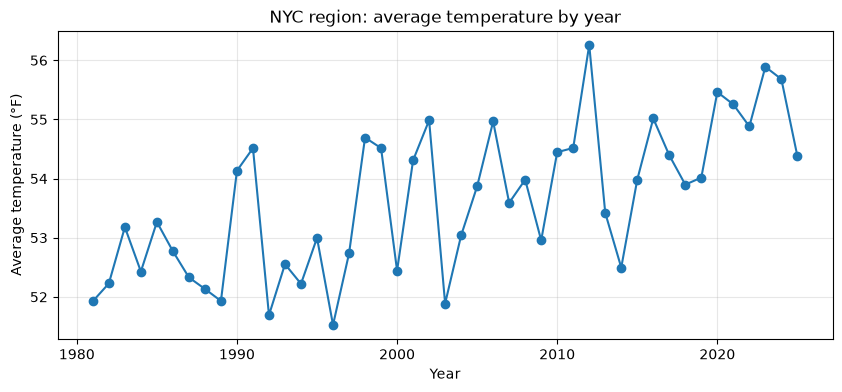

In [21]:
plt.figure(figsize=(10, 4))
plt.plot(yearly.index, yearly.values, marker="o")
plt.title("NYC region: average temperature by year")
plt.xlabel("Year")
plt.ylabel("Average temperature (°F)")
plt.grid(alpha=0.3)
plt.savefig("../docs/images/warming_trend.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
from sklearn.linear_model import LinearRegression

X = yearly.index.values.reshape(-1, 1)
y = yearly.values

model = LinearRegression()
model.fit(X, y)

slope = model.coef_[0]
print(f"Warming: {slope:.3f} °F per year")
print(f"That's {slope * 10:.2f} °F per decade")
print(f"About {slope * 44:.1f} °F total from 1981 to 2025")

Warming: 0.064 °F per year
That's 0.64 °F per decade
About 2.8 °F total from 1981 to 2025


In [9]:
model.predict([[2050]])

array([56.6567714])

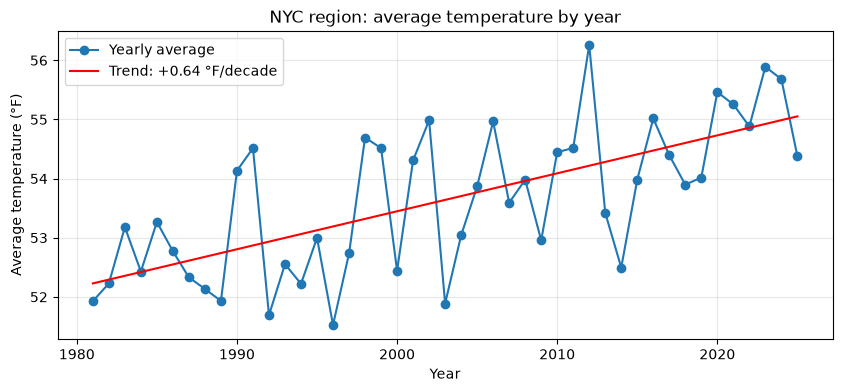

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(yearly.index, yearly.values, marker="o", label="Yearly average")
plt.plot(yearly.index, model.predict(X), color="red", label=f"Trend: +{slope*10:.2f} °F/decade")
plt.title("NYC region: average temperature by year")
plt.xlabel("Year")
plt.ylabel("Average temperature (°F)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
(yearly - model.predict(X)).abs().idxmax()

np.int32(2012)

In [12]:
print("Hottest high in the data:", round(df["T2M_MAX_F"].max(), 1), "°F")

hot90 = df["T2M_MAX_F"] >= 90
print("Days at or above 90°F:", hot90.sum())

Hottest high in the data: 93.6 °F
Days at or above 90°F: 4


In [13]:
print("Hottest high in the data:", round(df["T2M_MAX_F"].max(), 1), "°F")

hot85= df["T2M_MAX_F"] >= 85
print("Days at or above 85°F:", hot85.sum())

Hottest high in the data: 93.6 °F
Days at or above 85°F: 172


In [14]:
threshold = df["T2M_MAX_F"].quantile(0.95)
print("Hot-day threshold (95th percentile):", round(threshold, 1), "°F")

df["hot_day"] = df["T2M_MAX_F"] >= threshold
hot_days = df.groupby("year")["hot_day"].sum()
hot_days

Hot-day threshold (95th percentile): 81.0 °F


year
1981    18
1982    13
1983    25
1984     2
1985    11
1986     9
1987    10
1988    27
1989     5
1990     3
1991    23
1992     4
1993    22
1994    10
1995    32
1996     3
1997    12
1998    18
1999    36
2000     5
2001    16
2002    36
2003     9
2004     5
2005    33
2006    19
2007     8
2008    18
2009     9
2010    43
2011    23
2012    35
2013    13
2014     6
2015    25
2016    35
2017     7
2018    26
2019    21
2020    35
2021    13
2022    40
2023    20
2024    20
2025    24
Name: hot_day, dtype: int64

In [15]:
hot_days.idxmax()

np.int32(2010)

In [16]:
hot_days.max()

np.int64(43)

Hot days are changing by +3.0 days per decade


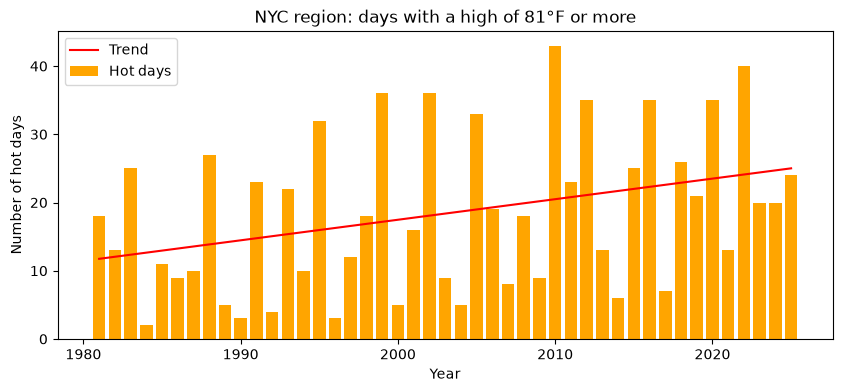

In [17]:
hot_model = LinearRegression()
hot_model.fit(X, hot_days.values)
hot_slope = hot_model.coef_[0]
print(f"Hot days are changing by {hot_slope * 10:+.1f} days per decade")

plt.figure(figsize=(10, 4))
plt.bar(hot_days.index, hot_days.values, color="orange", label="Hot days")
plt.plot(hot_days.index, hot_model.predict(X), color="red", label="Trend")
plt.title(f"NYC region: days with a high of {threshold:.0f}°F or more")
plt.xlabel("Year")
plt.ylabel("Number of hot days")
plt.legend()
plt.show()

In [18]:
hot_days.loc[1981:1990].mean()

np.float64(12.3)

In [20]:
hot_days.loc[2016:2025].mean()

np.float64(24.1)